In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("Environment ready!")

Environment ready!


In [7]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml(
    "mnist_784",
    version=1,
    return_X_y=True,
    as_frame=False
)

print("Data loaded successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Data loaded successfully!
X shape: (70000, 784)
y shape: (70000,)


In [8]:
print(X[0])
print("Label:", y[0])

[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255
 247 127   0   0   0   0   0   0   0   0   0   0   0   0  30  36  94 154
 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0   0   0
   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82
  82  56  39   0   0   0   0   0   0   0   0   0   0   0   0  18 219 253
 253 253 253 253 198 182 247 241   0   0   0   0   

In [9]:
X = X.astype(np.float32) / 255.0

print("Minimum:", X.min())
print("Maximum:", X.max())

Minimum: 0.0
Maximum: 1.0


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=10000,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 784)
Testing images: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)


In [11]:
# Network architecture
input_size = 784
hidden_size = 128
output_size = 10

# Initialize random weights
rng = np.random.default_rng(42)

W1 = rng.normal(
    0, np.sqrt(2 / input_size),
    (input_size, hidden_size)
)

b1 = np.zeros((1, hidden_size))

W2 = rng.normal(
    0, np.sqrt(2 / hidden_size),
    (hidden_size, output_size)
)

b2 = np.zeros((1, output_size))

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

W1: (784, 128)
b1: (1, 128)
W2: (128, 10)
b2: (1, 10)


In [12]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

In [13]:
values = np.array([-3, -1, 0, 2, 5])

print("Original:", values)
print("After ReLU:", relu(values))

Original: [-3 -1  0  2  5]
After ReLU: [0 0 0 2 5]


In [14]:
def forward(X):
    # Input → Hidden layer
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Hidden → Output layer
    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)

    return Z1, A1, A2

In [15]:
Z1, A1, A2 = forward(X_train[:1])

print("Predicted digit:", np.argmax(A2))
print("Actual digit:", y_train[0])
print("Probabilities:", A2)

Predicted digit: 7
Actual digit: 6
Probabilities: [[0.04230794 0.06108215 0.11974068 0.18862132 0.10064134 0.06372796
  0.08610403 0.22342339 0.03536596 0.07898524]]


In [16]:
def compute_loss(predictions, labels):
    m = len(labels)

    correct_probs = predictions[np.arange(m), labels.astype(int)]

    loss = -np.mean(np.log(np.clip(correct_probs, 1e-12, 1.0)))

    return loss


loss = compute_loss(A2, y_train[:1])

print("Loss:", loss)

Loss: 2.452199047554621


In [17]:
# Forward propagation on testing data
Z1, A1, A2 = forward(X_test)

# Select the digit with the highest probability
predictions = np.argmax(A2, axis=1)

# Compare predictions with actual labels
accuracy = np.mean(predictions == y_test.astype(int))

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 11.20%


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

X, y = fetch_openml(
    "mnist_784",
    version=1,
    return_X_y=True,
    as_frame=False
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [19]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (70000, 784)
y shape: (70000,)


In [20]:
X = X.astype(np.float32) / 255.0
y = y.astype(int)

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
import numpy as np

np.random.seed(42)

W1 = np.random.randn(784, 128) * np.sqrt(2 / 784)
b1 = np.zeros((1, 128))

W2 = np.random.randn(128, 10) * np.sqrt(2 / 128)
b2 = np.zeros((1, 10))

In [23]:
def relu(Z):
    return np.maximum(0, Z)

def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

In [24]:
def forward(X):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)

    return Z1, A1, A2

In [25]:
def compute_loss(predictions, labels):
    m = len(labels)

    correct_probs = predictions[
        np.arange(m), labels.astype(int)
    ]

    return -np.mean(np.log(np.clip(correct_probs, 1e-12, 1.0)))

In [26]:
def backward(X, y, Z1, A1, A2):
    global W1, b1, W2, b2

    m = X.shape[0]

    dZ2 = A2.copy()
    dZ2[np.arange(m), y.astype(int)] -= 1
    dZ2 /= m

    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [27]:
epochs = 20
learning_rate = 0.1
batch_size = 128

for epoch in range(epochs):
    indices = np.random.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size):
        batch_indices = indices[start:start + batch_size]

        X_batch = X_train[batch_indices]
        y_batch = y_train[batch_indices]

        # Forward propagation
        Z1, A1, A2 = forward(X_batch)

        # Backpropagation
        dW1, db1, dW2, db2 = backward(
            X_batch, y_batch, Z1, A1, A2
        )

        # Update weights and biases
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    # Calculate training metrics
    Z1, A1, A2 = forward(X_train)

    loss = compute_loss(A2, y_train)
    predictions = np.argmax(A2, axis=1)
    accuracy = np.mean(predictions == y_train)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- Loss: {loss:.4f} "
        f"- Accuracy: {accuracy * 100:.2f}%"
    )

Epoch 1/20 - Loss: 0.3484 - Accuracy: 89.43%
Epoch 2/20 - Loss: 0.2331 - Accuracy: 93.49%
Epoch 3/20 - Loss: 0.1913 - Accuracy: 94.64%
Epoch 4/20 - Loss: 0.1679 - Accuracy: 95.17%
Epoch 5/20 - Loss: 0.1458 - Accuracy: 95.93%
Epoch 6/20 - Loss: 0.1314 - Accuracy: 96.25%
Epoch 7/20 - Loss: 0.1173 - Accuracy: 96.67%
Epoch 8/20 - Loss: 0.1079 - Accuracy: 97.01%
Epoch 9/20 - Loss: 0.0947 - Accuracy: 97.34%
Epoch 10/20 - Loss: 0.0878 - Accuracy: 97.61%
Epoch 11/20 - Loss: 0.0826 - Accuracy: 97.74%
Epoch 12/20 - Loss: 0.0754 - Accuracy: 97.90%
Epoch 13/20 - Loss: 0.0712 - Accuracy: 98.05%
Epoch 14/20 - Loss: 0.0717 - Accuracy: 98.02%
Epoch 15/20 - Loss: 0.0636 - Accuracy: 98.31%
Epoch 16/20 - Loss: 0.0586 - Accuracy: 98.51%
Epoch 17/20 - Loss: 0.0560 - Accuracy: 98.56%
Epoch 18/20 - Loss: 0.0525 - Accuracy: 98.63%
Epoch 19/20 - Loss: 0.0495 - Accuracy: 98.76%
Epoch 20/20 - Loss: 0.0472 - Accuracy: 98.83%


In [28]:
Z1, A1, A2 = forward(X_test)

predictions = np.argmax(A2, axis=1)

accuracy = np.mean(predictions == y_test)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 97.48%


In [29]:
np.savez(
    "models/mnist_model.npz",
    W1=W1,
    b1=b1,
    W2=W2,
    b2=b2
)

print("Model saved successfully!")

Model saved successfully!


In [30]:
import numpy as np

# Load the archive file
model_data = np.load("models/mnist_model.npz")

# Extract the individual arrays
W1 = model_data["W1"]
b1 = model_data["b1"]
W2 = model_data["W2"]
b2 = model_data["b2"]

print("Model loaded successfully!")

Model loaded successfully!


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

print("Environment ready!")

X, y = fetch_openml(
    "mnist_784",
    version=1,
    return_X_y=True,
    as_frame=False
)

print("Dataset loaded successfully!")

Environment ready!
Dataset loaded successfully!


In [32]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("First label:", y[0])

X shape: (70000, 784)
y shape: (70000,)
First label: 5


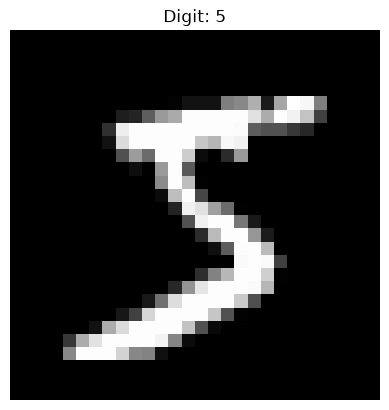

In [37]:
plt.imshow(X[0].reshape(28, 28), cmap="gray")
plt.title(f"Digit: {y[0]}")
plt.axis("off")
plt.show()

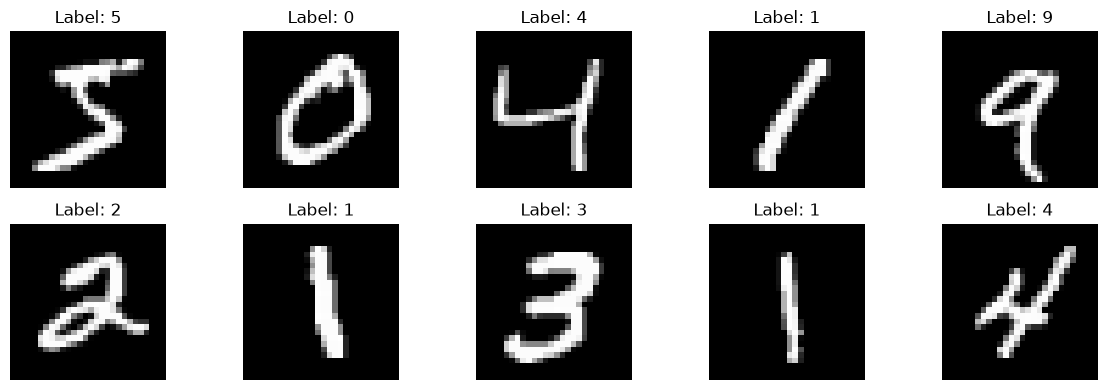

In [38]:
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
from sklearn.model_selection import train_test_split

# Normalize pixel values from 0–255 to 0–1
X = X / 255.0

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (56000, 784)
Testing images: (14000, 784)


In [40]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [41]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 92.11%


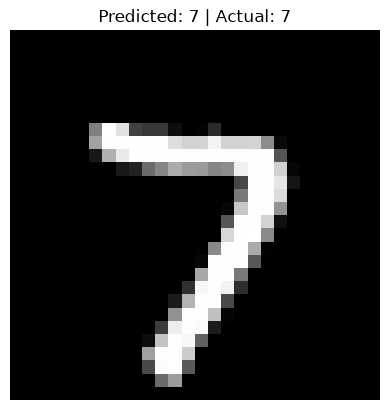

In [42]:
plt.imshow(X_test[0].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {y_pred[0]} | Actual: {y_test[0]}")
plt.axis("off")
plt.show()

In [51]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    max_iter=20,
    random_state=42,
    early_stopping=True
)

mlp_model.fit(X_train, y_train)

print("Neural Network training completed!")

Neural Network training completed!


/home/c5/Desktop/projects/Handwritten-Digit-Recognition-Model/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


In [55]:
mlp_pred = mlp_model.predict(X_test)

mlp_accuracy = accuracy_score(y_test, mlp_pred)

print(f"Neural Network Accuracy: {mlp_accuracy * 100:.2f}%")

Neural Network Accuracy: 97.56%


In [56]:
print("Logistic Regression:", f"{accuracy * 100:.2f}%")
print("Neural Network:", f"{mlp_accuracy * 100:.2f}%")

Logistic Regression: 92.11%
Neural Network: 97.56%


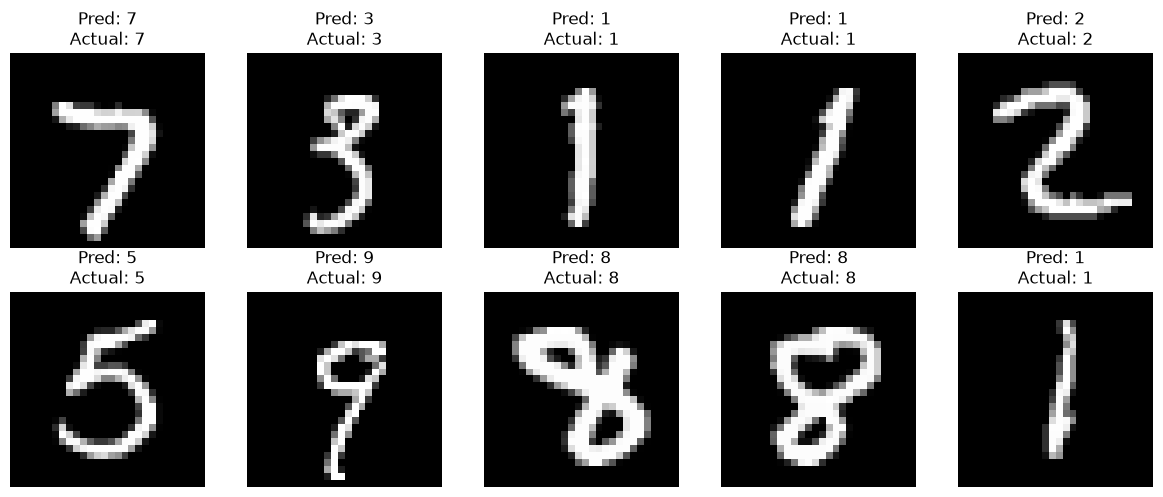

In [57]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Pred: {mlp_pred[i]}\nActual: {y_test[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Total incorrect predictions: 342


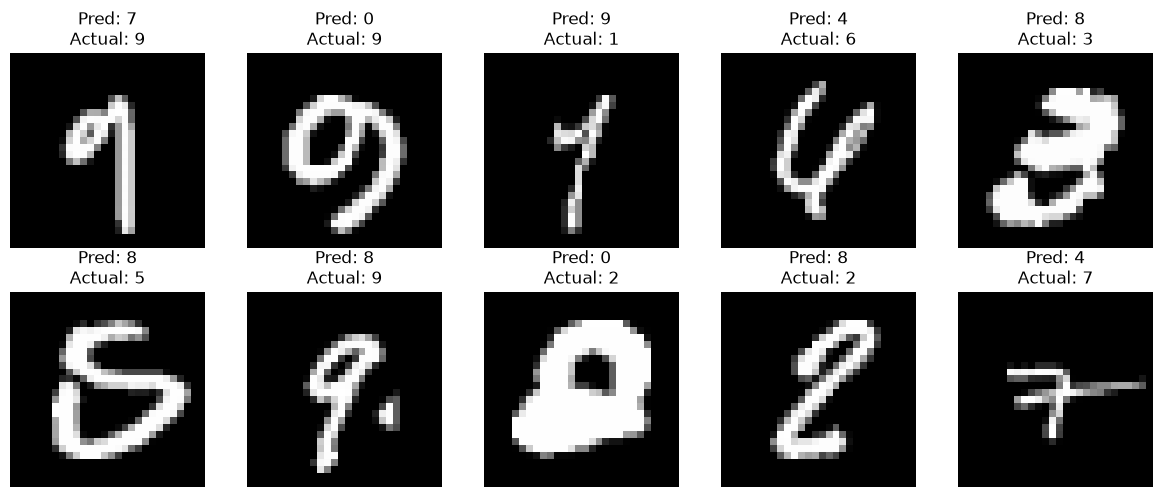

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# Find incorrect predictions
incorrect = np.where(mlp_pred != y_test)[0]

print("Total incorrect predictions:", len(incorrect))

# Display the first 10 incorrect predictions
plt.figure(figsize=(12, 5))

for i, idx in enumerate(incorrect[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    plt.title(f"Pred: {mlp_pred[idx]}\nActual: {y_test[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

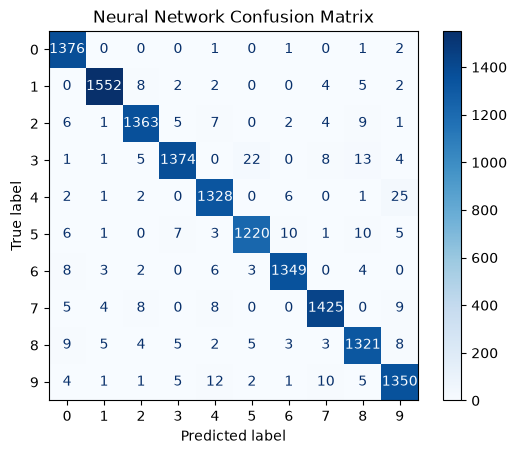

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    mlp_pred,
    cmap="Blues"
)

plt.title("Neural Network Confusion Matrix")
plt.show()

In [60]:
from sklearn.metrics import classification_report

print(classification_report(y_test, mlp_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1381
           1       0.99      0.99      0.99      1575
           2       0.98      0.97      0.98      1398
           3       0.98      0.96      0.97      1428
           4       0.97      0.97      0.97      1365
           5       0.97      0.97      0.97      1263
           6       0.98      0.98      0.98      1375
           7       0.98      0.98      0.98      1459
           8       0.96      0.97      0.97      1365
           9       0.96      0.97      0.97      1391

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



In [61]:
import joblib

joblib.dump(mlp_model, "mnist_neural_network.pkl")

print("Model saved successfully!")

Model saved successfully!


In [62]:
import joblib

loaded_model = joblib.load("mnist_neural_network.pkl")

prediction = loaded_model.predict(X_test[:1])

print("Predicted digit:", prediction[0])
print("Actual digit:", y_test[0])

Predicted digit: 7
Actual digit: 7


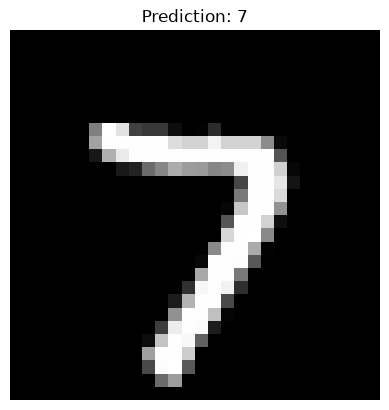

In [63]:
import matplotlib.pyplot as plt

plt.imshow(X_test[0].reshape(28, 28), cmap="gray")
plt.title(f"Prediction: {prediction[0]}")
plt.axis("off")
plt.show()

In [64]:
pip install streamlit pillow joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 3.9 MB/s eta 0:00:00MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 6.6 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 7.0 MB/s eta 0:00:000:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [streamlit]37m━━━ 11/12 [streamlit]
Note: you may need to restart the kernel to use updated packages.


In [65]:
import streamlit as st
import numpy as np
from PIL import Image, ImageOps
import joblib

# Load trained model
model = joblib.load("mnist_neural_network.pkl")

st.title("Handwritten Digit Recognition")
st.write("Upload an image of a handwritten digit (0–9).")

uploaded_file = st.file_uploader(
    "Choose an image",
    type=["png", "jpg", "jpeg"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("L")

    st.image(image, caption="Uploaded Image", width=200)

    # Resize to MNIST dimensions
    image = ImageOps.fit(image, (28, 28))

    # Convert image to NumPy array
    image_array = np.array(image)

    # MNIST expects bright digits on a dark background
    # Invert uploaded images with a light background
    if np.mean(image_array) > 127:
        image_array = 255 - image_array

    # Normalize pixel values
    image_array = image_array / 255.0

    # Flatten into 784 features
    image_array = image_array.reshape(1, 784)

    # Predict digit
    prediction = model.predict(image_array)

    st.success(f"Predicted Digit: {prediction[0]}")

2026-10-20 08:28:16.548 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 08:28:16.693 
  command:

    streamlit run /home/c5/Desktop/projects/Handwritten-Digit-Recognition-Model/.venv/lib/python3.13/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-10-20 08:28:16.694 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 08:28:16.695 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 08:28:16.696 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 08:28:16.698 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 08:28:16.698 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare